In [1]:
%matplotlib inline
# %matplotlib qt
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time
import matplotlib
from astropy.coordinates import SkyCoord

/home/thassan/Paquetes/last_version/magic_spysii/magic_spysii/sim_run.py:381: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if k is 0:


In [2]:
# Gaia DR2 parallax: 
star_parallax = [1.212719100939012-0.04877213641946521, 1.212719100939012, 1.212719100939012+0.04877213641946521] * u.mas
star_distance = (1/star_parallax.to('mas').value) * 1000 * u.pc
star_distance

<Quantity [859.14567457, 824.59326255, 792.71260108] pc>

In [3]:
# Gaia DR3 parallax: 1.091953080183618
star_parallax = [1.091953080183618-0.027456844, 1.091953080183618, 1.091953080183618+0.027456844] * u.mas
star_distance = (1/star_parallax.to('mas').value) * 1000 * u.pc
star_distance

<Quantity [939.41149438, 915.79026439, 893.32779565] pc>

In [4]:
# From David Green:
star_distance = 806 * u.pc

In [5]:
# Let's assume that the radius of the photosphere ranges between 10**12 - 10**13 cm
radii = [1e12, 5e12, 8e12] * u.cm
angular_diams = (2*radii.to('m'))/star_distance.to('m') * u.radian
angular_diams.to('mas')

<Quantity [0.16587065, 0.82935324, 1.32696519] mas>

In [1]:
fig = plt.figure(figsize=(15, 9))
ax1 = fig.add_subplot(111)

magnitude = 2

simulations = []
for i, angular_diam in enumerate(angular_diams):
    simulations.append(SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC"))
    simulations[i].target_b_mag = magnitude
    simulations[i].stellar_diameter = angular_diam

    times = ['2022-04-01T23:00:00',
             '2022-04-02T00:00:00', 
             '2022-04-02T02:00:00',  
             '2022-04-02T04:00:00', 
             '2022-04-02T05:00:00']
    time_array = Time(times, format='isot', scale='utc')

    simulations[i].simulate_observations(time_array, run_duration=10*u.min)
    simulations[i].add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

    simulations[i].fit_uniform_disc()
    simulations[i].plot_v2(color="C{}".format(i), set_log_yscale=False, axis=ax1, plot_legend=False)    
    
plt.text(75, 2.5, r'Photosphere radius ~ $10^{12}$ cm', ha="center", family='sans-serif', size=20)
plt.text(100, 0.7, r'~ $5\cdot10^{12}$ cm', ha="center", family='sans-serif', size=20)
plt.text(15, 0.2, r'~ $8\cdot10^{12}$ cm', ha="center", family='sans-serif', size=20)
fig.savefig("T_Crb_simulation_{}_mags.pdf".format(magnitude))
plt.show()

NameError: name 'plt' is not defined

In [6]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 3
sim_run.stellar_diameter = 0.16587065 * u.mas

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


In [7]:
times = ['2022-05-01T22:00:00',
         '2022-05-01T23:00:00',
         '2022-05-02T00:00:00',
         '2022-05-02T01:00:00', 
         '2022-05-02T02:00:00', 
         '2022-05-02T03:00:00', 
         '2022-05-02T04:00:00', 
         '2022-05-02T05:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

In [8]:
sim_run.simulate_observations(time_array, run_duration=20*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

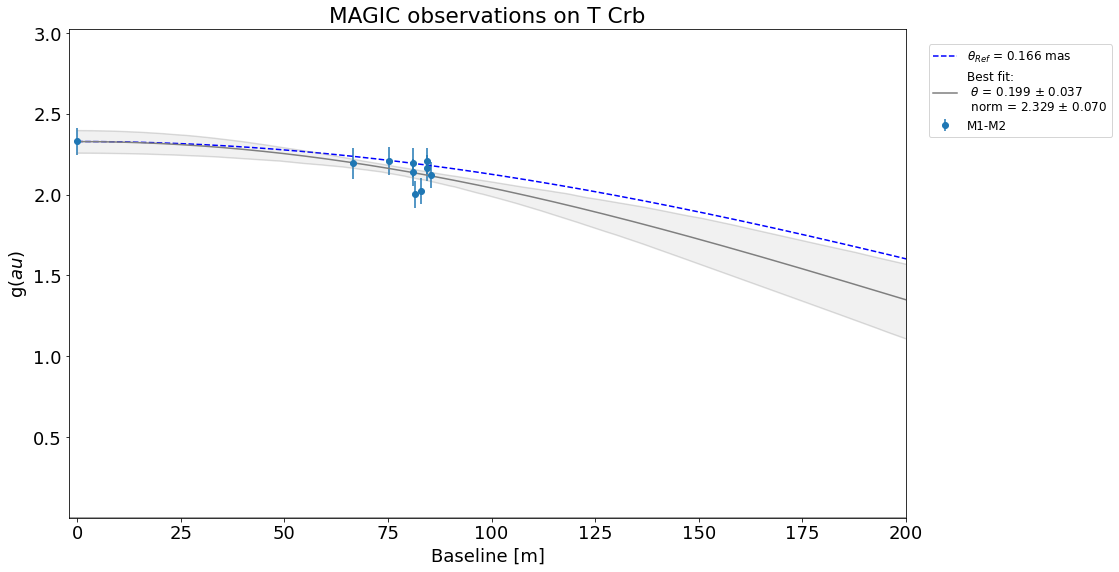

In [9]:
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

In [9]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 3
sim_run.stellar_diameter = 0.16587065 * u.mas

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


In [11]:
times = ['2022-05-01T22:00:00',
         '2022-05-01T23:00:00',
         '2022-05-02T00:00:00',
         '2022-05-02T01:00:00', 
         '2022-05-02T02:00:00', 
         '2022-05-02T03:00:00', 
         '2022-05-02T04:00:00', 
         '2022-05-02T05:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

In [12]:
sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

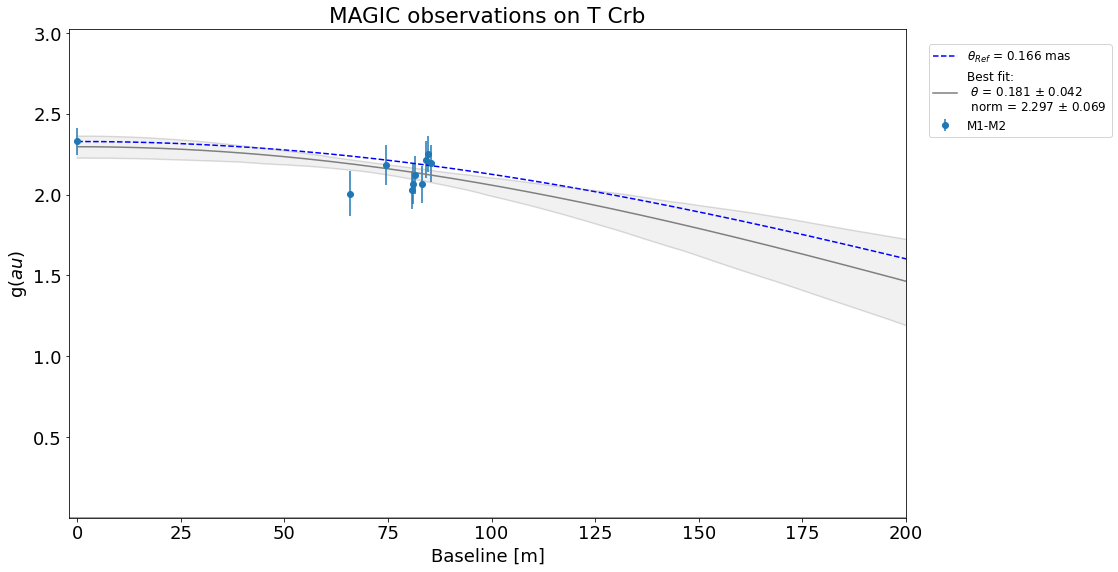

In [13]:
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


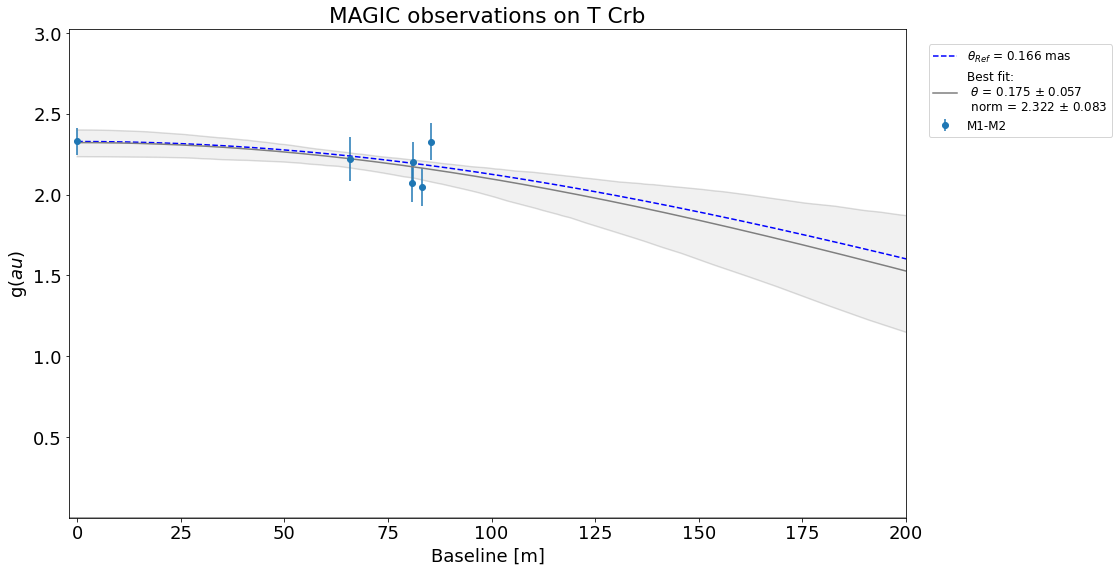

In [27]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 3
sim_run.stellar_diameter = 0.16587065 * u.mas

times = ['2022-05-01T22:00:00',
         '2022-05-02T00:00:00', 
         '2022-05-02T02:00:00',  
         '2022-05-02T04:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


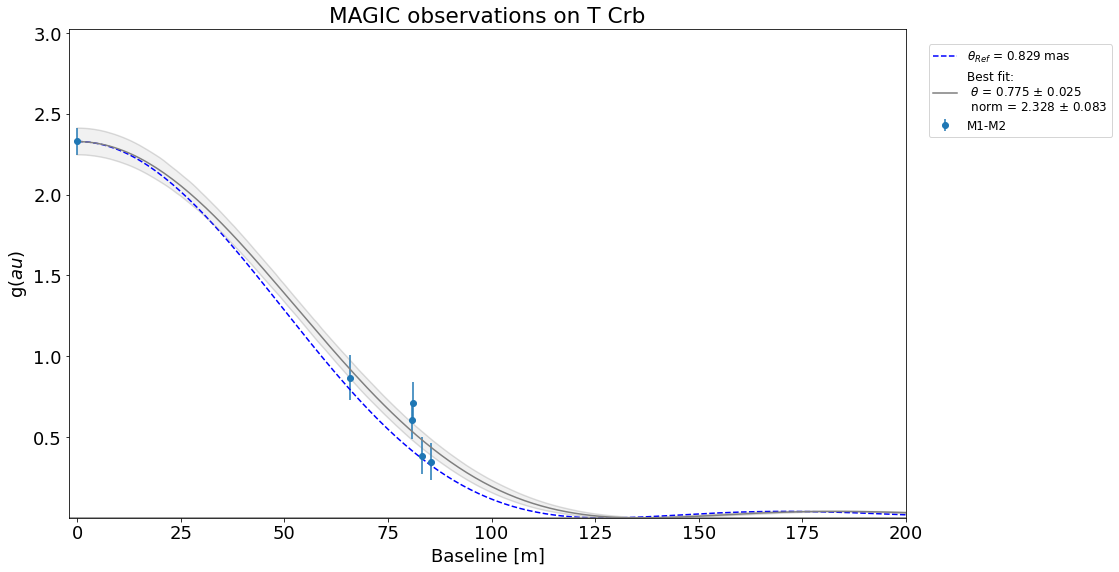

In [32]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 3
sim_run.stellar_diameter = 0.82935324 * u.mas

times = ['2022-05-01T22:00:00',
         '2022-05-02T00:00:00', 
         '2022-05-02T02:00:00',  
         '2022-05-02T04:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


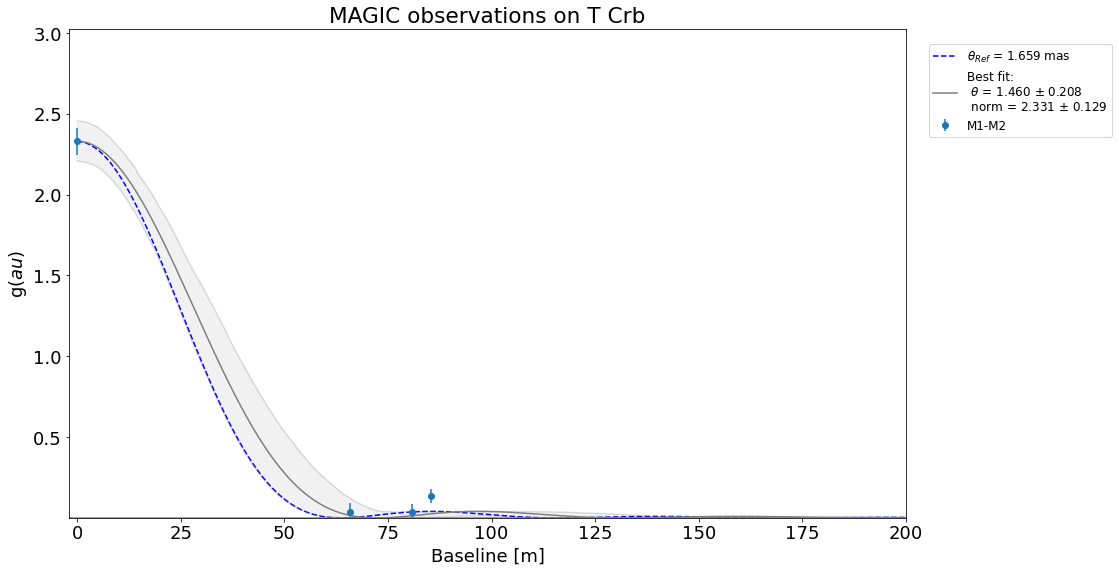

In [24]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 2
sim_run.stellar_diameter = 1.6587065 * u.mas

times = ['2022-05-01T22:00:00',
         '2022-05-02T00:00:00', 
         '2022-05-02T02:00:00',  
         '2022-05-02T04:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


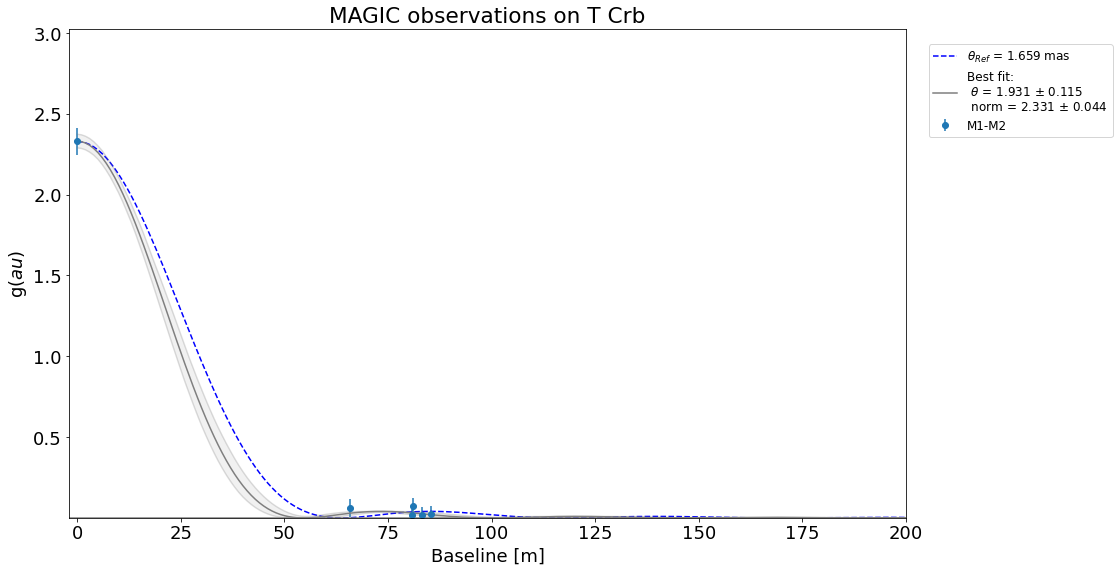

In [22]:
sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
sim_run.target_b_mag = 2
sim_run.stellar_diameter = 1.6587065 * u.mas

times = ['2022-05-01T22:00:00',
         '2022-05-02T00:00:00', 
         '2022-05-02T02:00:00',  
         '2022-05-02T04:00:00', 
         '2022-05-02T06:00:00']
time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=10*u.min)
sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=False)

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (239.87567594, 25.92017038)>
Closest star found within the JMDC is:
 -Star ids: HD143107 or --
- Stellar diameter: 2.85


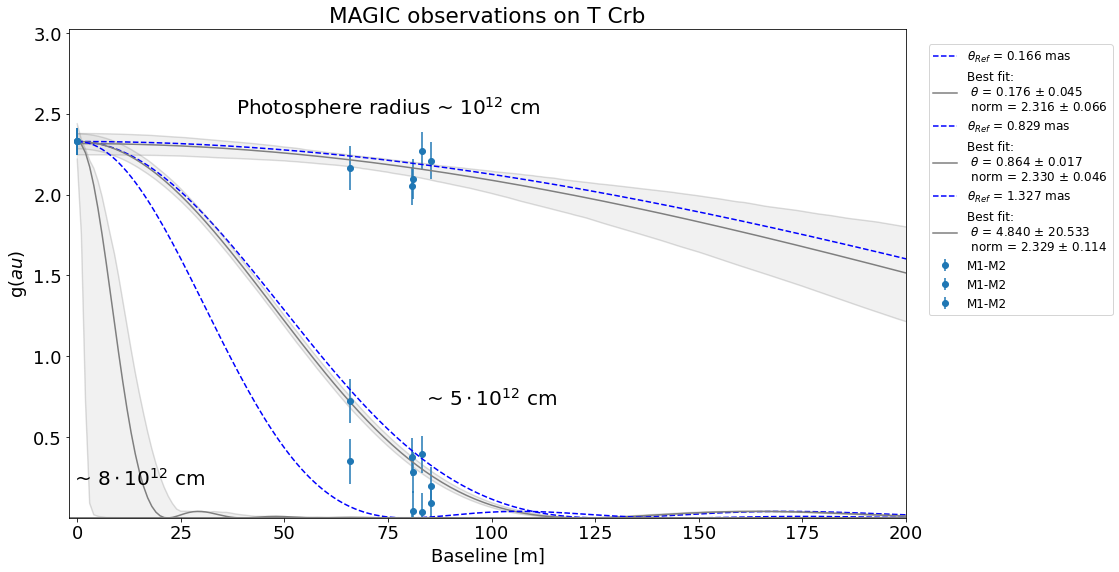

In [34]:
fig = plt.figure(figsize=(15, 9))
ax1 = fig.add_subplot(111)

magnitude = 3

for angular_diam in angular_diams:
    sim_run = SimulateSiiRuns("T Crb", zbc_norm=2.329, observatory_name="MAGIC")
    sim_run.target_b_mag = magnitude
    sim_run.stellar_diameter = angular_diam

    times = ['2022-05-01T22:00:00',
             '2022-05-02T00:00:00', 
             '2022-05-02T02:00:00',  
             '2022-05-02T04:00:00', 
             '2022-05-02T06:00:00']
    time_array = Time(times, format='isot', scale='utc')

    sim_run.simulate_observations(time_array, run_duration=10*u.min)
    sim_run.add_zbc_measurement(2.329, 0.083, ["M1", "M2"])

    sim_run.fit_uniform_disc()
    sim_run.plot_v2(set_log_yscale=False, axis=ax1)    
    
plt.text(75, 2.5, r'Photosphere radius ~ $10^{12}$ cm', ha="center", family='sans-serif', size=20)
plt.text(100, 0.7, r'~ $5\cdot10^{12}$ cm', ha="center", family='sans-serif', size=20)
plt.text(15, 0.2, r'~ $8\cdot10^{12}$ cm', ha="center", family='sans-serif', size=20)
plt.show()